In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt 
%matplotlib inline

from matplotlib import* 
import seaborn as sns

In [2]:
import tensorflow as tf
from tensorflow import keras

In [3]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

In [4]:
np.random.seed(19)
tf.random.set_seed(19)

In [5]:
import datetime

Stage 1: Combine the Ask and Bid time series into one DataFrame (10 marks)
What you can change: the file names in SETTINGS. Nothing else.

In [6]:
df_2023_Ask = pd.read_csv("XAGUSD_5 Mins_Ask_2023.01.01_2023.06.30-1.csv")
df_2023_Bid = pd.read_csv("XAGUSD_5 Mins_Bid_2023.01.01_2023.06.30-1.csv")

In [7]:
print(df_2023_Ask.head(3))
print(df_2023_Ask.tail(3))

            Time (UTC)    Open    High     Low   Close  Volume 
0  2023.01.02 23:00:00  24.102  24.125  24.083  24.125    0.351
1  2023.01.02 23:05:00  24.094  24.188  24.094  24.141    1.155
2  2023.01.02 23:10:00  24.143  24.148  24.022  24.027    0.882
                Time (UTC)    Open    High     Low   Close  Volume 
35217  2023.06.30 20:45:00  22.781  22.781  22.776  22.776   0.4212
35218  2023.06.30 20:50:00  22.776  22.797  22.774  22.786   0.6836
35219  2023.06.30 20:55:00  22.786  22.811  22.786  22.811   0.3712


In [8]:
print(df_2023_Bid.head(3))
print(df_2023_Bid.tail(3))

            Time (UTC)    Open    High     Low   Close  Volume 
0  2023.01.02 23:00:00  24.036  24.059  24.017  24.059   0.3480
1  2023.01.02 23:05:00  24.064  24.130  24.064  24.092   1.8458
2  2023.01.02 23:10:00  24.094  24.098  23.972  23.977   0.9030
                Time (UTC)    Open    High     Low   Close  Volume 
35217  2023.06.30 20:45:00  22.751  22.751  22.746  22.746    0.069
35218  2023.06.30 20:50:00  22.746  22.761  22.736  22.756    0.216
35219  2023.06.30 20:55:00  22.756  22.766  22.701  22.745    0.327


In [9]:
df_2023_Ask.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  str    
 1   Open        35220 non-null  float64
 2   High        35220 non-null  float64
 3   Low         35220 non-null  float64
 4   Close       35220 non-null  float64
 5   Volume      35220 non-null  float64
dtypes: float64(5), str(1)
memory usage: 2.3 MB


In [10]:
df_2023_Bid.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  str    
 1   Open        35220 non-null  float64
 2   High        35220 non-null  float64
 3   Low         35220 non-null  float64
 4   Close       35220 non-null  float64
 5   Volume      35220 non-null  float64
dtypes: float64(5), str(1)
memory usage: 2.3 MB


In [11]:
df_2023 = df_2023_Bid.merge(df_2023_Ask, left_on='Time (UTC)', right_on='Time (UTC)', how='outer')
df_2023

,Time (UTC),Open_x,High_x,Low_x,Close_x,Volume _x,Open_y,High_y,Low_y,Close_y,Volume _y
0,2023.01.02 23:00:00,24.036,24.059,24.017,24.059,0.3480,24.102,24.125,24.083,24.125,0.3510
1,2023.01.02 23:05:00,24.064,24.130,24.064,24.092,1.8458,24.094,24.188,24.094,24.141,1.1550
2,2023.01.02 23:10:00,24.094,24.098,23.972,23.977,0.9030,24.143,24.148,24.022,24.027,0.8820
3,2023.01.02 23:15:00,23.977,23.980,23.938,23.980,0.8940,24.026,24.028,23.986,24.028,0.8940
4,2023.01.02 23:20:00,23.978,24.024,23.976,24.023,0.8880,24.026,24.073,24.023,24.073,0.9044
...,...,...,...,...,...,...,...,...,...,...,...
35215,2023.06.30 20:35:00,22.752,22.752,22.741,22.746,0.2752,22.782,22.782,22.771,22.776,1.8002
35216,2023.06.30 20:40:00,22.736,22.751,22.736,22.746,0.1410,22.775,22.781,22.775,22.776,0.7568
35217,2023.06.30 20:45:00,22.751,22.751,22.746,22.746,0.0690,22.781,22.781,22.776,22.776,0.4212
35218,2023.06.30 20:50:00,22.746,22.761,22.736,22.756,0.2160,22.776,22.797,22.774,22.786,0.6836


In [12]:
df_2023.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  str    
 1   Open_x      35220 non-null  float64
 2   High_x      35220 non-null  float64
 3   Low_x       35220 non-null  float64
 4   Close_x     35220 non-null  float64
 5   Volume _x   35220 non-null  float64
 6   Open_y      35220 non-null  float64
 7   High_y      35220 non-null  float64
 8   Low_y       35220 non-null  float64
 9   Close_y     35220 non-null  float64
 10  Volume _y   35220 non-null  float64
dtypes: float64(10), str(1)
memory usage: 3.6 MB


In [13]:
# Time = T, Bid = B, Ask = A
df_2023.columns = ['Local_T', 'Open_B', 'High_B', 'Low_B', 'Close_B', 'Volume_B',
                   'Open_A', 'High_A', 'Low_A', 'Close_A', 'Volume_A']


In [14]:
file_obj2 = open('df_2023.csv', 'w')
df_2023.to_csv('df_2023.csv', encoding='utf-8', index=False)
file_obj2.close()

In [15]:
df = pd.read_csv('df_2023.csv', low_memory=False, sep=',')

Stage 2: Preprocessing, graphs and histograms (10 marks)
Delta columns (Ask minus Bid), time to date-time, price and volume charts, then the new day and new week markers.

What you can change:

1.bins=100, the column names, the titles and the colours in the charts.
2.iloc[0:70] in the candlestick chart: the rows to show.
3.The markers use BAR_MINUTES from SETTINGS, so nothing else changes for another time-frame.

In [16]:
# Delta = D
df['Volume_D'] = df['Volume_A'] - df['Volume_B']
df['Volume_D_abs'] = (df['Volume_A'] - df['Volume_B']).abs()

In [17]:
df['Open_D'] = df['Open_A'] - df['Open_B']
df['High_D'] = df['High_A'] - df['High_B']
df['Low_D'] = df['Low_A'] - df['Low_B']
df['Close_D'] = df['Close_A'] - df['Close_B']

In [18]:
data = df.drop(['Open_A', 'High_A', 'Low_A', 'Close_A'], axis=1)

In [19]:
data['Local_T_T'] = pd.to_datetime(data['Local_T'], utc=True)

In [20]:
data=data.drop(['Local_T'],axis=1)

In [21]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   Open_B        35220 non-null  float64            
 1   High_B        35220 non-null  float64            
 2   Low_B         35220 non-null  float64            
 3   Close_B       35220 non-null  float64            
 4   Volume_B      35220 non-null  float64            
 5   Volume_A      35220 non-null  float64            
 6   Volume_D      35220 non-null  float64            
 7   Volume_D_abs  35220 non-null  float64            
 8   Open_D        35220 non-null  float64            
 9   High_D        35220 non-null  float64            
 10  Low_D         35220 non-null  float64            
 11  Close_D       35220 non-null  float64            
 12  Local_T_T     35220 non-null  datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), float64(12)
memory usage: 3.5 MB


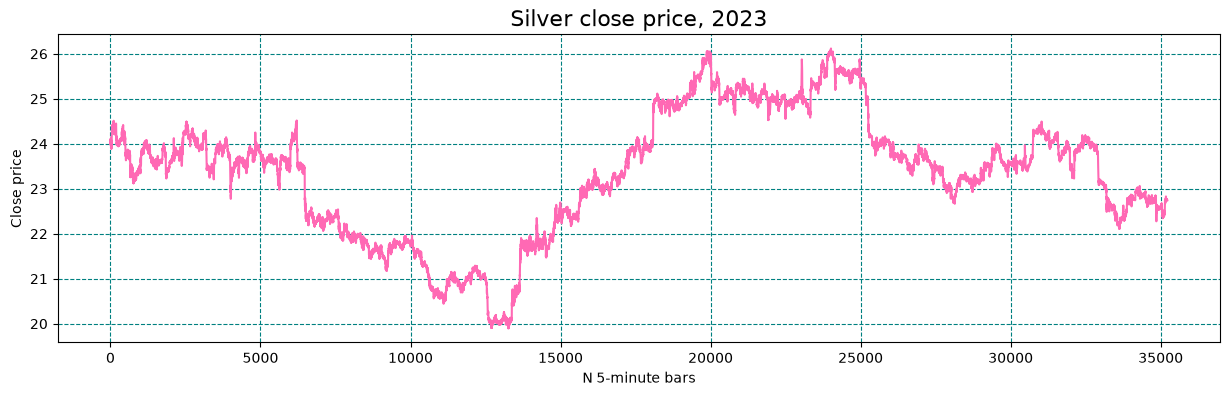

In [22]:
plt.figure(figsize=(15,4))
plt.plot(data['Close_B'], color='hotpink', linewidth=1.5)
plt.title('Silver close price, 2023', size=16)
plt.xlabel('N 5-minute bars')
plt.ylabel('Close price')
plt.grid(True, color='teal', linestyle='--')
plt.show()

In [23]:
data_chart = data.set_index('Local_T_T', inplace=False)

In [24]:
data_chart = data_chart.drop(['Volume_A', 'Volume_D', 'Volume_D_abs', 
                        'Open_D', 'High_D', 'Low_D', 'Close_D'],axis=1)

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


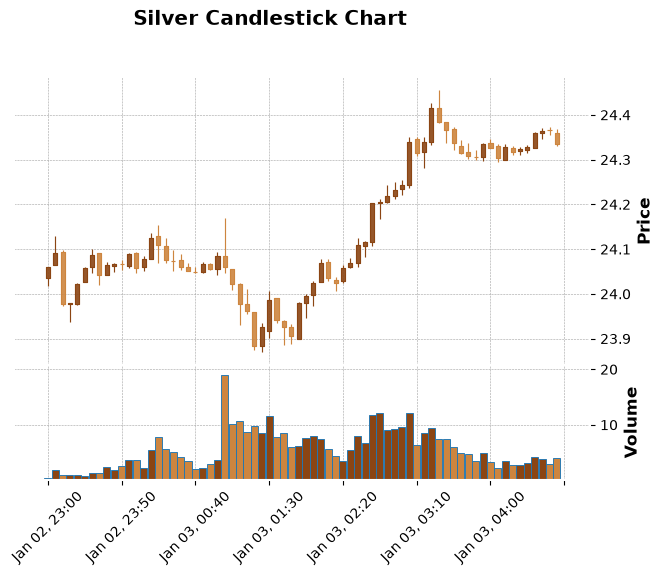

In [25]:
import mplfinance as mpf

data_chart.columns = ['Open', 'High', 'Low', 'Close', 'Volume']
mc = mpf.make_marketcolors(up='saddlebrown', down='peru', edge='inherit', wick='inherit', volume='inherit')
my_style = mpf.make_mpf_style(base_mpf_style='charles', marketcolors=mc)
mpf.plot(data_chart.iloc[0:70], type='candle', style=my_style, title='Silver Candlestick Chart', volume=True)


In [26]:
data_chart =[]

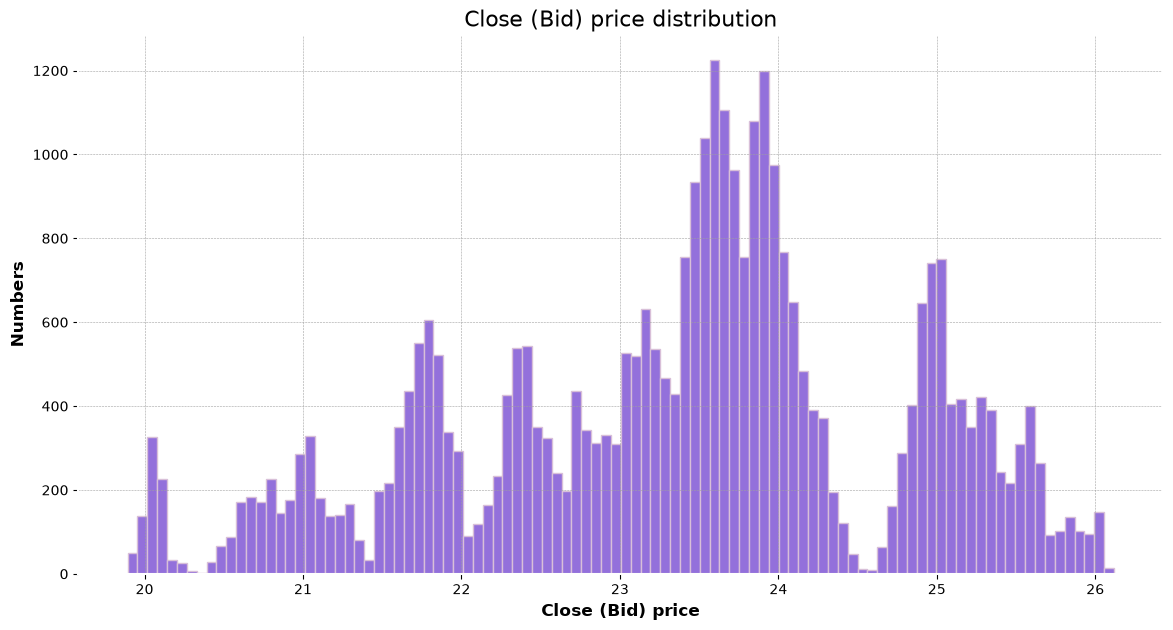

In [27]:
plt.figure(num=1,figsize=(14,7))
plt.hist(data['Close_B'],bins=100, color = 'mediumpurple', edgecolor = 'thistle')
plt.title('Close (Bid) price distribution',size=16)
plt.ylabel('Numbers',size=12)
plt.xlabel('Close (Bid) price',size=12)
plt.show()

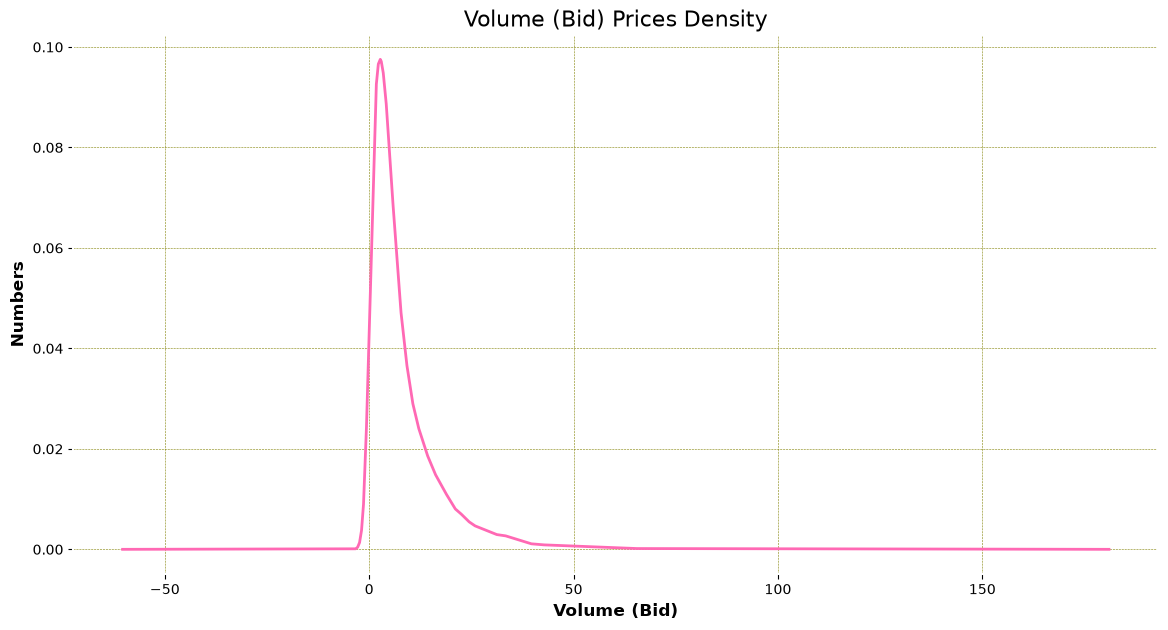

In [28]:
plt.figure(num=1,figsize=(14,7))
data['Volume_B'].plot.kde(color = 'hotpink', linewidth=2)
plt.title('Volume (Bid) Prices Density',size=16)
plt.ylabel('Numbers',size=12)
plt.xlabel('Volume (Bid)', size=12)
plt.grid(True, color='olive', linestyle='--')
plt.show()

findfont: Failed to find font weight semibold, now using 700.


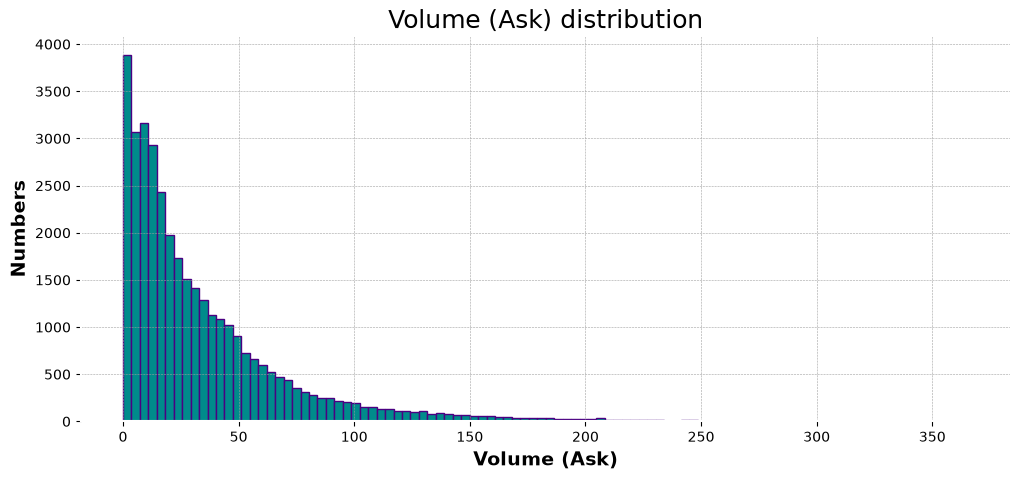

In [29]:
plt.figure(num=1,figsize=(12,5))
plt.hist(data['Volume_A'],bins=100, color='darkcyan', edgecolor='indigo')
plt.title('Volume (Ask) distribution',size=18)
plt.ylabel('Numbers',size=14)
plt.xlabel('Volume (Ask)',size=14)
plt.show()

In [30]:
# Extra

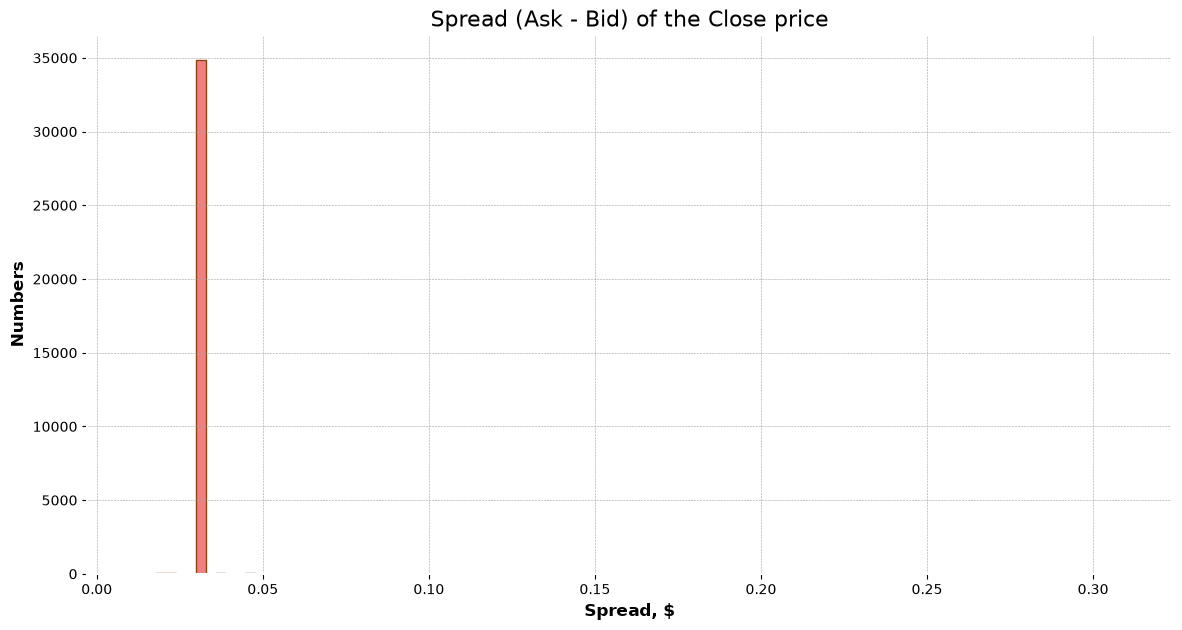

In [31]:
plt.figure(num=1, figsize=(14,7))
plt.hist(data['Close_D'], bins=100, color='lightcoral', edgecolor='saddlebrown')
plt.title('Spread (Ask - Bid) of the Close price', size=16)
plt.ylabel('Numbers', size=12)
plt.xlabel('Spread, $', size=12)
plt.show()

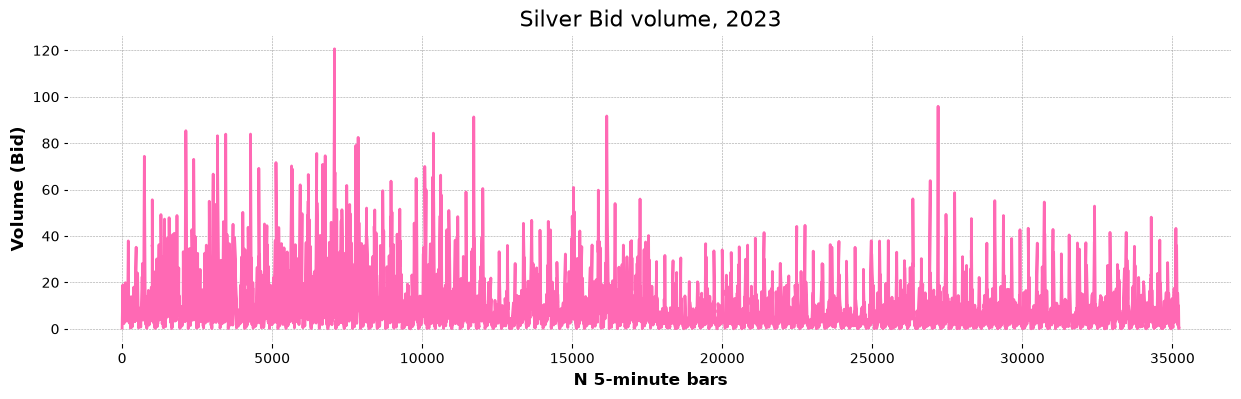

In [32]:
plt.figure(figsize=(15,4))
plt.plot(data['Volume_B'], color='hotpink')
plt.title('Silver Bid volume, 2023', size=16)
plt.xlabel('N 5-minute bars')
plt.ylabel('Volume (Bid)')
plt.show()

In [33]:
print(df_2023.shape)
print(df_2023.isna().sum().sum(), 'missing values')

(35220, 11)
0 missing values


In [34]:
data['Local_T_T_shipt_1_Down'] = data['Local_T_T'].shift(1)

In [35]:
data["Local_T_T_Delta"] = data["Local_T_T"] - data["Local_T_T_shipt_1_Down"]

In [36]:
data.loc[data.index[0], 'Local_T_T_Delta'] = '2 days 01:05:00'
data['Local_T_T_Delta'].iloc[0]

Timedelta('2 days 01:05:00')

In [37]:
data[['Local_T_T_Delta']][data["Local_T_T_Delta"] > '0 days 00:05:00'].value_counts(sort=False)

Local_T_T_Delta
2 days 01:05:00    24
0 days 01:05:00    99
0 days 05:05:00     1
2 days 00:05:00     1
3 days 01:05:00     1
0 days 03:35:00     2
Name: count, dtype: int64

In [38]:
data['New_day'] = 0
data['New_week'] = 0

In [39]:
data.loc[data["Local_T_T_Delta"] > '0 days 00:05:00', 'New_day'] = 1

In [40]:
data.loc[data["Local_T_T_Delta"] >'1 days 00:00:00', 'New_week'] = 1

In [41]:
data2 = data.drop(['Local_T_T', 'Local_T_T_shipt_1_Down', 'Local_T_T_Delta'],axis=1)

In [42]:
data2['Y_High_B'] = data2['High_B']
data2['Y_Low_A'] = data2['Low_B'] + data2['Low_D']

Stage 3: Normalisation (10 marks)
Prices: (x - min) / (max - min). Volumes: x / max volume. Spreads (deltas): (max - x) / (max - min), so a small spread gives a number close to 1. The min and max come from the training part only, so the model never sees the future.

What you can change: TRAIN_SHARE in SETTINGS. If the question asks for another normalisation (for example prices ÷ 100), change only the price formulas. 

In [43]:
data_length = len(data)
data_length

35220

In [44]:
train_size = int(round(data_length*0.8, -3))
train_size

28000

In [45]:
train = data.iloc[:train_size]
train.shape

(28000, 17)

In [46]:
max_price = (train['High_B'] + train['High_D']).max()
max_price

np.float64(26.153)

In [47]:
min_price = train['Low_B'].min()
min_price

np.float64(19.888)

In [48]:
max_volume = max(max(train['Volume_B']), max(train['Volume_A']))
max_volume

365.6322

In [49]:
max_Delta = max(max(train['Open_D']), max(train['High_D']), max(train['Low_D']), max(train['Close_D']))
max_Delta

0.30900000000000105

In [50]:
max_Delta = round(max_Delta, 3)
max_Delta

0.309

In [51]:
min_Delta = min(min(train['Open_D']), min(train['High_D']), min(train['Low_D']), min(train['Close_D'])) 
min_Delta

0.0009999999999976694

In [52]:
min_Delta = round(min_Delta, 3) 
min_Delta

0.001

In [53]:
max_volume_Delta = train['Volume_D'].max()
max_volume_Delta

np.float64(317.5858)

In [54]:
min_volume_Delta = train['Volume_D'].min()
min_volume_Delta

np.float64(-48.7912)

In [55]:
max_volume_Delta_abs = train['Volume_D_abs'].max() 
max_volume_Delta_abs

np.float64(317.5858)

In [56]:
min_volume_Delta_abs = train['Volume_D_abs'].min()
min_volume_Delta_abs

np.float64(0.0)

In [57]:
data2['Open_B'] = ( data2['Open_B'] - min_price ) / (max_price-min_price)
data2['High_B']  = ( data2['High_B']  - min_price ) / (max_price-min_price)
data2['Low_B']   = ( data2['Low_B']   - min_price ) / (max_price-min_price)
data2['Close_B'] = ( data2['Close_B'] - min_price ) / (max_price-min_price)
data2['Y_High_B'] = ( data2['Y_High_B'] - min_price ) / (max_price-min_price)
data2['Y_Low_A']  = ( data2['Y_Low_A']  - min_price ) / (max_price-min_price)

In [58]:
data2['Volume_A']  = data2['Volume_A'] / max_volume
data2['Volume_B']  = data2['Volume_B'] / max_volume

In [59]:
data2['Volume_D'] = ( data2['Volume_D'] - min_volume_Delta ) / (max_volume_Delta-min_volume_Delta)

In [60]:
data2['Volume_D_abs']  = data2['Volume_D_abs'] / max_volume_Delta_abs

In [61]:
data2['Open_D']  = ( max_Delta - data2['Open_D'] )  / (max_Delta-min_Delta)
data2['High_D']  = ( max_Delta - data2['High_D'] )  / (max_Delta-min_Delta)
data2['Low_D']   = ( max_Delta - data2['Low_D'] )   / (max_Delta-min_Delta)
data2['Close_D'] = ( max_Delta - data2['Close_D'] ) / (max_Delta-min_Delta)

In [62]:
data2.head()

,Open_B,High_B,Low_B,Close_B,Volume_B,Volume_A,Volume_D,Volume_D_abs,Open_D,High_D,Low_D,Close_D,New_day,New_week,Y_High_B,Y_Low_A
0,0.662091,0.665762,0.659058,0.665762,0.000952,0.000960,0.133180,0.000009,0.788961,0.788961,0.788961,0.788961,1,1,0.665762,0.669593
1,0.666560,0.677095,0.666560,0.671030,0.005048,0.003159,0.131287,0.002175,0.905844,0.814935,0.905844,0.844156,0,0,0.677095,0.671349
2,0.671349,0.671987,0.651875,0.652674,0.002470,0.002412,0.133115,0.000066,0.844156,0.840909,0.840909,0.840909,0,0,0.671987,0.659856
3,0.652674,0.653152,0.646449,0.653152,0.002445,0.002445,0.133172,0.000000,0.844156,0.847403,0.847403,0.847403,0,0,0.653152,0.654110
4,0.652833,0.660176,0.652514,0.660016,0.002429,0.002474,0.133217,0.000052,0.847403,0.844156,0.850649,0.840909,0,0,0.660176,0.660016


In [63]:
pd.set_option('display.max_columns', None)
cols = ['Open_B','High_B','Low_B','Close_B','Volume_B','Volume_A',
        'Volume_D','Volume_D_abs','Open_D','High_D','Low_D','Close_D']
print(data2.iloc[:train_size][cols].describe().loc[['min','max']].round(3))   # training part: inside 0 to 1
print(data2.iloc[train_size:][cols].describe().loc[['min','max']].round(3))   # test part: may go slightly outside

back = data2['Close_B'] * (max_price - min_price) + min_price
print((back - data['Close_B']).abs().max())                                   # must be about 0

     Open_B  High_B  Low_B  Close_B  Volume_B  Volume_A  Volume_D  \
min   0.001   0.004  0.000    0.001      0.00       0.0       0.0   
max   0.994   0.995  0.991    0.994      0.33       1.0       1.0   

     Volume_D_abs  Open_D  High_D  Low_D  Close_D  
min           0.0   0.403   0.282  0.107   -0.000  
max           1.0   0.955   0.945  1.000    0.951  
     Open_B  High_B  Low_B  Close_B  Volume_B  Volume_A  Volume_D  \
min   0.354   0.356  0.353    0.355     0.000     0.000     0.122   
max   0.736   0.739  0.730    0.735     0.151     0.698     0.752   

     Volume_D_abs  Open_D  High_D  Low_D  Close_D  
min         0.000   0.659   0.640 -0.325    0.123  
max         0.714   0.968   0.938  0.971    0.964  
0.0


In [64]:
columns_float =['Open_B', 'High_B', 'Low_B', 'Close_B', 
                'Volume_B', 'Volume_A', 'Volume_D', 'Volume_D_abs', 
                'Open_D', 'High_D', 'Low_D', 'Close_D',
                'Y_High_B', 'Y_Low_A']

columns_integer =['New_day', 'New_week']

In [65]:
for column in columns_float:
    data2[column] = pd.to_numeric(data2[column], downcast='float')

for column in columns_integer:
    data2[column] = pd.to_numeric(data2[column], downcast='integer')

data2.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open_B        35220 non-null  float32
 1   High_B        35220 non-null  float32
 2   Low_B         35220 non-null  float32
 3   Close_B       35220 non-null  float32
 4   Volume_B      35220 non-null  float32
 5   Volume_A      35220 non-null  float32
 6   Volume_D      35220 non-null  float32
 7   Volume_D_abs  35220 non-null  float32
 8   Open_D        35220 non-null  float32
 9   High_D        35220 non-null  float32
 10  Low_D         35220 non-null  float32
 11  Close_D       35220 non-null  float32
 12  New_day       35220 non-null  int8   
 13  New_week      35220 non-null  int8   
 14  Y_High_B      35220 non-null  float32
 15  Y_Low_A       35220 non-null  float32
dtypes: float32(14), int8(2)
memory usage: 1.9 MB


In [66]:
file_obj1 = open('XAGUSD_2023_5Min_normalised.csv', 'w')
data2.to_csv('XAGUSD_2023_5Min_normalised.csv', encoding='utf-8', index=False)
file_obj1.close()

Stage 4: Shift the min and max prices, inputs and outputs, 3D tensor, split (10 marks)
The answers are the highest high_bid and lowest low_ask over the next WINDOW bars (25 minutes here). Each example is a window of the last N bars.

What you can change: HORIZON_MINUTES, BAR_MINUTES, N, N_SMALL, TEST_SIZE in SETTINGS. WINDOW is calculated from them and is used in the three places that need it.

Run the delete-last-rows cells only once. shuffle=False stays for a time series.

In [67]:
data = pd.read_csv('XAGUSD_2023_5Min_normalised.csv', low_memory=False, sep=',')   
data.head()

,Open_B,High_B,Low_B,Close_B,Volume_B,Volume_A,Volume_D,Volume_D_abs,Open_D,High_D,Low_D,Close_D,New_day,New_week,Y_High_B,Y_Low_A
0,0.662091,0.665762,0.659058,0.665762,0.000952,0.000960,0.133180,0.000009,0.788961,0.788961,0.788961,0.788961,1,1,0.665762,0.669593
1,0.666560,0.677095,0.666560,0.671029,0.005048,0.003159,0.131287,0.002175,0.905844,0.814935,0.905844,0.844156,0,0,0.677095,0.671349
2,0.671349,0.671987,0.651876,0.652674,0.002470,0.002412,0.133115,0.000066,0.844156,0.840909,0.840909,0.840909,0,0,0.671987,0.659856
3,0.652674,0.653152,0.646449,0.653152,0.002445,0.002445,0.133172,0.000000,0.844156,0.847403,0.847403,0.847403,0,0,0.653152,0.654110
4,0.652833,0.660176,0.652514,0.660016,0.002429,0.002474,0.133217,0.000052,0.847403,0.844156,0.850649,0.840909,0,0,0.660176,0.660016


In [68]:
for column in columns_float:
    data[column] = pd.to_numeric(data[column], downcast='float')

for column in columns_integer:
    data[column] = pd.to_numeric(data[column], downcast='integer')

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open_B        35220 non-null  float32
 1   High_B        35220 non-null  float32
 2   Low_B         35220 non-null  float32
 3   Close_B       35220 non-null  float32
 4   Volume_B      35220 non-null  float32
 5   Volume_A      35220 non-null  float32
 6   Volume_D      35220 non-null  float32
 7   Volume_D_abs  35220 non-null  float32
 8   Open_D        35220 non-null  float32
 9   High_D        35220 non-null  float32
 10  Low_D         35220 non-null  float32
 11  Close_D       35220 non-null  float32
 12  New_day       35220 non-null  int8   
 13  New_week      35220 non-null  int8   
 14  Y_High_B      35220 non-null  float32
 15  Y_Low_A       35220 non-null  float32
dtypes: float32(14), int8(2)
memory usage: 1.9 MB


In [69]:
n=data.shape[0]
n

35220

In [70]:
p=data.shape[1]
p

16

In [71]:
data_ax = data.drop(['Y_High_B', 'Y_Low_A'], axis=1)

In [72]:
data_ay = data[['Y_High_B', 'Y_Low_A']]

In [73]:
data_ay = data_ay.shift(-1)

In [74]:
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=5)

data_ay['Y_High_B_5'] = data_ay['Y_High_B'].rolling(window=indexer).max()
data_ay['Y_Low_A_5']  = data_ay['Y_Low_A'].rolling(window=indexer).min()

In [75]:
data_ay = data_ay.drop(['Y_High_B', 'Y_Low_A'],axis=1)

In [76]:
for i in range(5):
        data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

In [77]:
for i in range(5):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

In [78]:
data_a = np.array(data_ax) 

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])  
    print('\n')
    print(data_a[-2:,:]) 

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

data_a:
[[6.6209e-01 6.6576e-01 6.5906e-01 6.6576e-01 9.5178e-04 9.5998e-04
  1.3318e-01 9.4463e-06 7.8896e-01 7.8896e-01 7.8896e-01 7.8896e-01
  1.0000e+00 1.0000e+00]
 [6.6656e-01 6.7709e-01 6.6656e-01 6.7103e-01 5.0482e-03 3.1589e-03
  1.3129e-01 2.1752e-03 9.0584e-01 8.1494e-01 9.0584e-01 8.4416e-01
  0.0000e+00 0.0000e+00]]


[[0.4541 0.4563 0.4533 0.4555 0.0053 0.0095 0.1374 0.0049 0.9058 0.9058
  0.9058 0.9058 0.     0.    ]
 [0.4555 0.4571 0.4551 0.4571 0.001  0.004  0.1362 0.0034 0.9058 0.9058
  0.9058 0.9058 0.     0.    ]]
numpy size: =  (35215, 14)
type:  float32


In [79]:
data_y = np.array(data_ay) 

print("data_a:")
print(data_y[:3,:])  
print('\n')
print(data_y[-3:,:]) 

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

data_a:
[[0.677095   0.65411013]
 [0.6724661  0.65411013]
 [0.6724661  0.65411013]]


[[0.45714286 0.45810056]
 [0.45857942 0.45985633]
 [0.4593775  0.46017557]]
numpy size: =  (35215, 2)
type:  float64


In [80]:
from tqdm import tqdm

In [81]:
n_small = 30000

N=50

L=n_small-N
t=data_a.shape[1]
print('Size of a three-dimensional inputs tensor: ',L,N,t)

Size of a three-dimensional inputs tensor:  29950 50 14


In [82]:
data_b = np.zeros( (L, N, t), dtype= 'float32' )

In [83]:
Y = np.zeros((L, 2), dtype= 'float32')

In [84]:
print('L = n_small - N - 5 = ', n_small-N-5, L)

for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k+N, :]   
                                          
    Y[k,0] = data_y[k+N-1,0]  
    
    Y[k,1] = data_y[k+N-1,1]   

print(k) 
    
print("Numpy size:        ", data_b.shape, '\n')

print( Y[:5,:])
print( Y[-10:,:])
print(      "Numpy size:         ", Y.shape)

L = n_small - N - 5 =  29945 29950


100%|██████████| 29950/29950 [00:00<00:00, 73707.33it/s]

29949
Numpy size:         (29950, 50, 14) 

[[0.72897047 0.7061452 ]
 [0.72897047 0.7061452 ]
 [0.72897047 0.71093374]
 [0.72897047 0.7093376 ]
 [0.7177973  0.7088587 ]]
[[0.5905826  0.5896249 ]
 [0.590423   0.5896249 ]
 [0.58946526 0.5896249 ]
 [0.58930564 0.5896249 ]
 [0.588348   0.5896249 ]
 [0.588348   0.5897845 ]
 [0.58754987 0.5897845 ]
 [0.58754987 0.5897845 ]
 [0.58754987 0.5899441 ]
 [0.58754987 0.5899441 ]]
Numpy size:          (29950, 2)


In [85]:
import random

pp = random.randint(50, L-20) # (any number before 29950) - just to look at the middle of data_b
print('random int = ', pp)

print('data_b:', '\t\t','Y:')
print('Y_High_B ','\t\t','Y_High_B')

for i in range(15):
    print(data_b[pp+i,N-1,1], '\t\t', Y[pp+i,0])

random int =  18502
data_b: 		 Y:
Y_High_B  		 Y_High_B
0.7913807 		 0.8012769
0.79010373 		 0.8012769
0.7912211 		 0.8017558
0.7964884 		 0.8036712
0.79872304 		 0.8078212
0.8012769 		 0.809577
0.80015963 		 0.809577
0.8017558 		 0.809577
0.8036712 		 0.809577
0.8078212 		 0.809577
0.809577 		 0.80877894
0.80877894 		 0.8071828
0.8055866 		 0.8071828
0.8046289 		 0.8071828
0.8051077 		 0.8071828


In [86]:
filled = (np.abs(data_b).sum(axis=(1, 2)) > 0).sum()
print(filled, L)

29950 29950


In [87]:
data = []
data_ax = []
data_ay = []
data_a = []
data_y = []

In [88]:
from sklearn.model_selection import train_test_split

In [89]:
X_train, X_test, y_train, y_test = train_test_split(data_b, Y, test_size=0.1,
                                                   shuffle = False, stratify = None, random_state=101)

In [90]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(26955, 50, 14)
(26955, 2)
(2995, 50, 14)
(2995, 2)


Stage 5: Neural network architecture (10 marks)
LSTM is active. To switch the model:

Put # in front of the LSTM settings lines and the LSTM model lines.
Remove the # from the settings line and the model block of the model you want.
Model	summary() total	Steps per epoch
LSTM	46,202	1213
MLP	212,610	2157
CNN	44,027	719
input_shape=(N, t) reads the numbers from your data. You can change the units, filters, kernel sizes or add layers.

In [91]:
model = keras.Sequential([
    keras.layers.LSTM(100, activation='relu', input_shape=(N, t)),  
    keras.layers.Dense(2)
])

C:\Users\Arshpreet Singh\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [92]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100)            │        46,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           202 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,202 (180.48 KB)

 Trainable params: 46,202 (180.48 KB)

 Non-trainable params: 0 (0.00 B)

None


In [93]:
model.compile(optimizer="adam", loss="mse", metrics=["mae"]
             )

Stage 6: Train the neural network (20 marks)
Early stopping stops the training when the validation error stops improving. The best model is saved in a file named after NAME, so models never overwrite each other. Run the training cell once and leave its output on screen.

In [94]:
es = EarlyStopping(monitor='val_loss', mode='min', patience=5, verbose=1)
mc = ModelCheckpoint('best_model_LSTM_SILVER.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)   

In [95]:
history = model.fit(X_train, y_train, batch_size=20, epochs=10,
                    validation_split=0.1, shuffle=True,
                    verbose=1, callbacks=[es,mc])

Epoch 1/10
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0013 - mae: 0.0121
Epoch 1: val_loss improved from None to 0.00009, saving model to best_model_LSTM_SILVER.keras

Epoch 1: finished saving model to best_model_LSTM_SILVER.keras
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - loss: 0.0013 - mae: 0.0121 - val_loss: 8.7529e-05 - val_mae: 0.0061
Epoch 2/10
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 9.8816e-05 - mae: 0.0070
Epoch 2: val_loss improved from 0.00009 to 0.00008, saving model to best_model_LSTM_SILVER.keras

Epoch 2: finished saving model to best_model_LSTM_SILVER.keras
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 133s 110ms/step - loss: 9.8816e-05 - mae: 0.0070 - val_loss: 8.3973e-05 - val_mae: 0.0061
Epoch 3/10
1212/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - loss: 8.8689e-05 - mae: 0.0067
Epoch 3: val_loss improved from 0.00008 to 0.00007, saving model to best_model_LSTM_SILVER.keras

Epoch 3: finished saving model to best_model_LSTM_SILVER.keras
1213/1213 ━━━━━━━━━━━━

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



Stage 7: Graph of the training process (10 marks)
What you can change: the colours and titles. 'loss' is the MSE and 'mae' is the MAE.

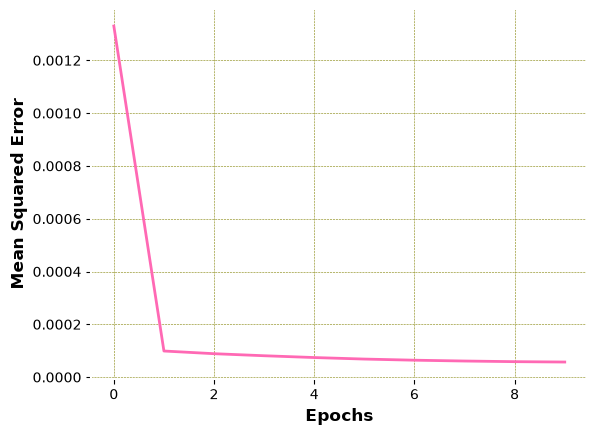

In [96]:
plt.plot(history.history['loss'], color = 'hotpink')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.grid(True, color='olive', linestyle='--')
plt.show()

findfont: Failed to find font weight semibold, now using 700.


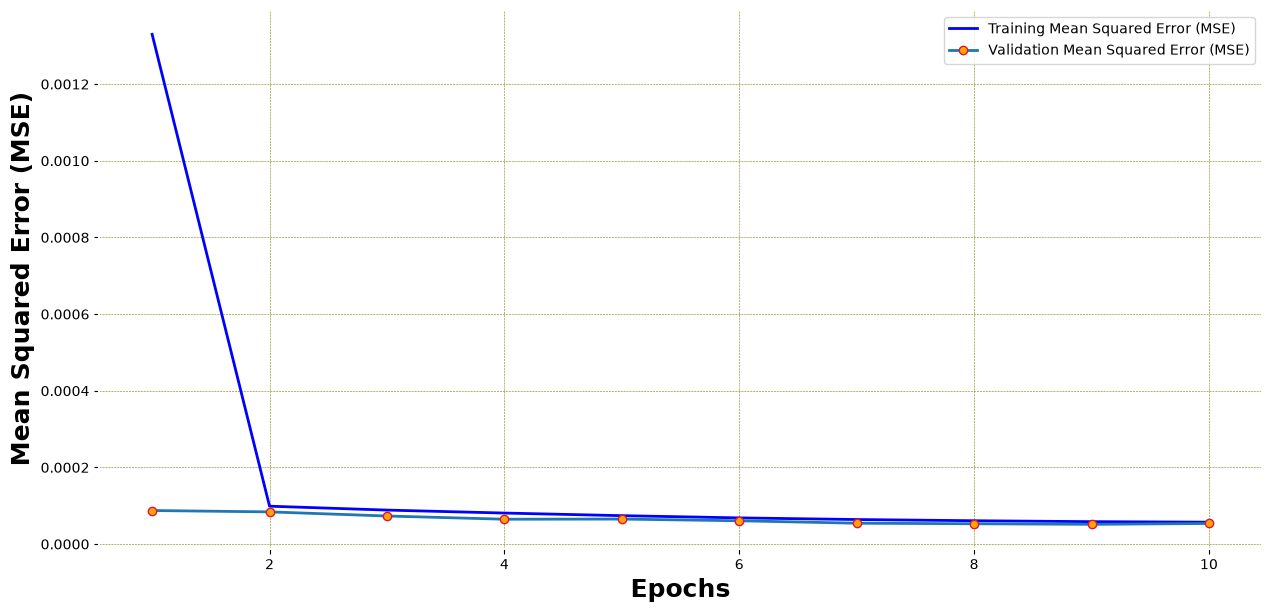

In [97]:
history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='crimson', markerfacecolor='orange', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.grid(True, color='olive', linestyle='--')
plt.legend()
plt.show()

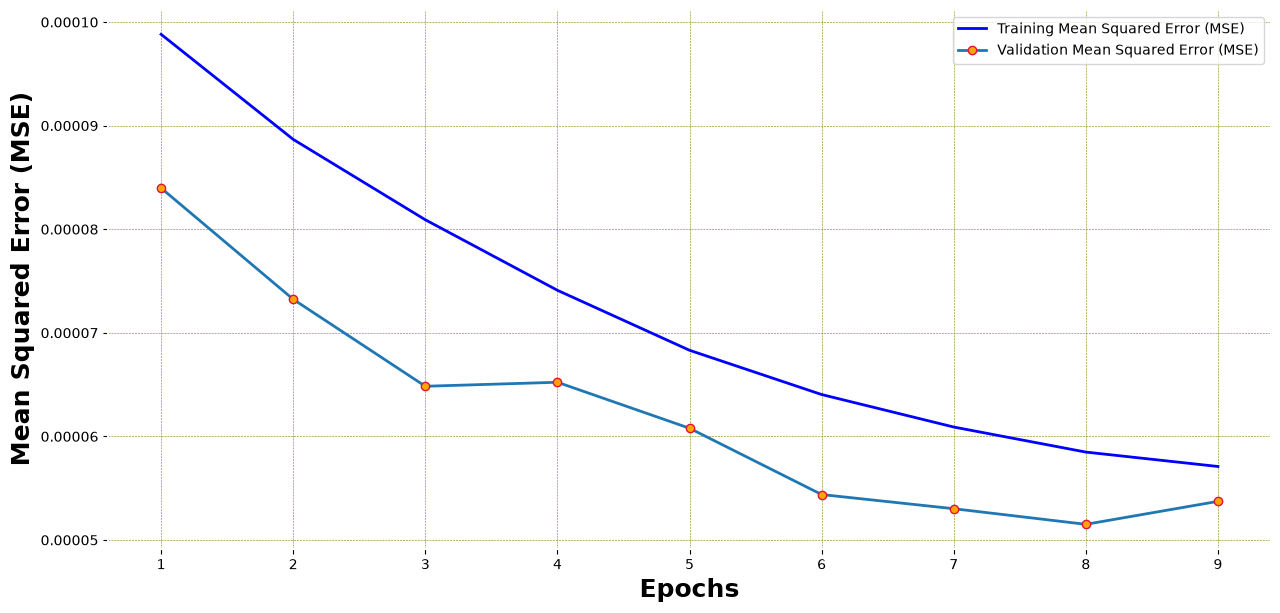

In [98]:
history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='crimson', markerfacecolor='orange', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.grid(True, color='olive', linestyle='--')
plt.legend()
plt.show()

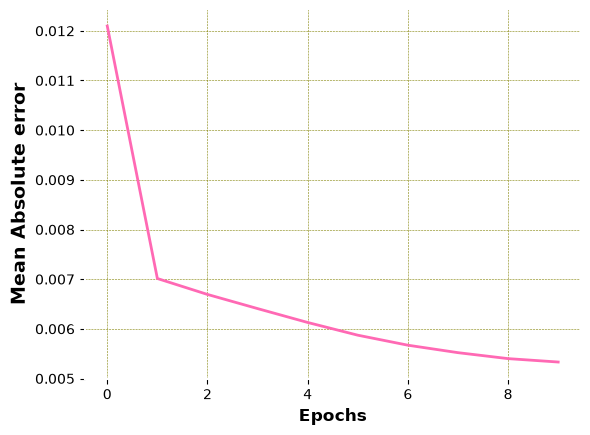

In [99]:
plt.plot(history.history['mae'], color='hotpink')
plt.xlabel('Epochs')
plt.ylabel('Mean Absolute error',size=14)
plt.grid(True, color='olive', linestyle='--')
plt.show()

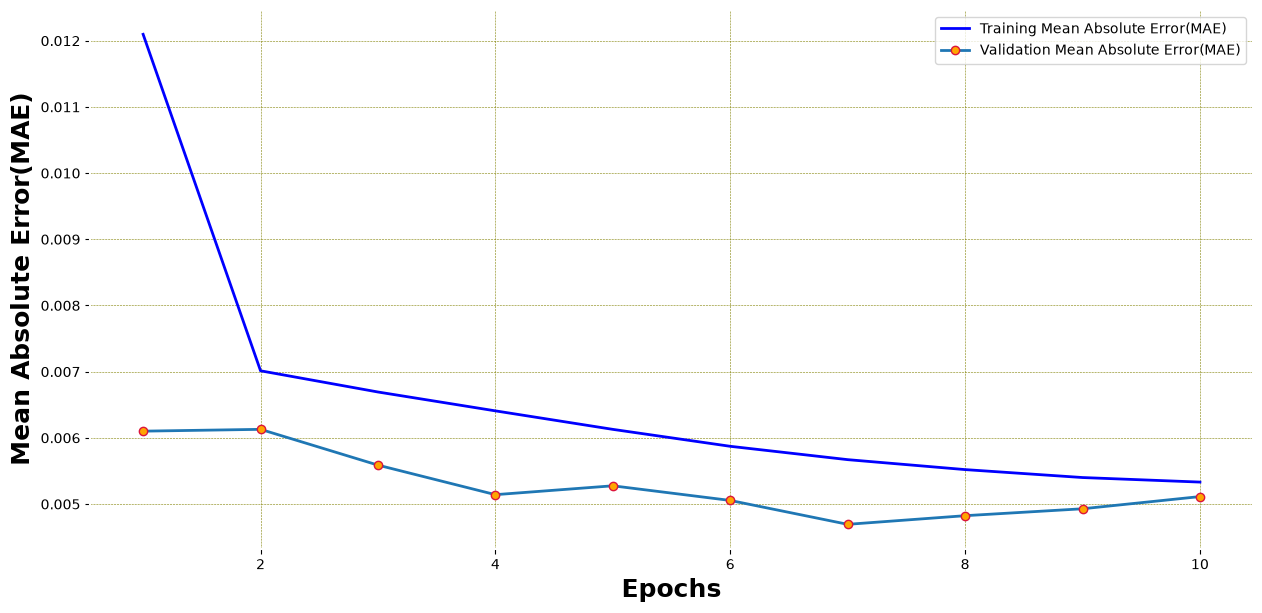

In [100]:
history_dict = history.history

mae_values = history_dict['mae']
val_mae_values = history_dict['val_mae']

epochs = range(1, len(mae_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mae_values, 'b', label='Training Mean Absolute Error(MAE)')
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor='crimson', markerfacecolor='orange', label='Validation Mean Absolute Error(MAE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Absolute Error(MAE)', size=18)
plt.grid(True, color='olive', linestyle='--')
plt.legend()
plt.show()

Stage 8: MSE and MAE on the test data (10 marks)
The scores come from the saved best model. The MAE in dollars is the normalised MAE times (price_max - price_min).

In [101]:
LSTM_saved_best_model = keras.models.load_model('best_model_LSTM_SILVER.keras') 

In [102]:
scores = LSTM_saved_best_model.evaluate(X_test, y_test, verbose=1)

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 3.9614e-05 - mae: 0.0045


In [103]:
scores

[3.961406400776468e-05, 0.004513260908424854]

In [104]:
print("Mean squared error (mse): %.9f " % (scores[0]))

Mean squared error (mse): 0.000039614 


In [105]:
print("Mean absolute error (mae): %.9f " % (scores[1]))

Mean absolute error (mae): 0.004513261 


Stage 9: Additional graphs and predicted prices (10 marks)
What you can change: N1 (first row), LL (how many rows), the colours and the titles. N1 + LL must be below the number of test rows.

In [106]:
pred = LSTM_saved_best_model(X_test)
print(pred)

tf.Tensor(
[[0.63006043 0.6293801 ]
 [0.6308632  0.6305001 ]
 [0.6318503  0.6317334 ]
 ...
 [0.5859051  0.5857178 ]
 [0.5855013  0.5854478 ]
 [0.5856557  0.5858016 ]], shape=(2995, 2), dtype=float32)


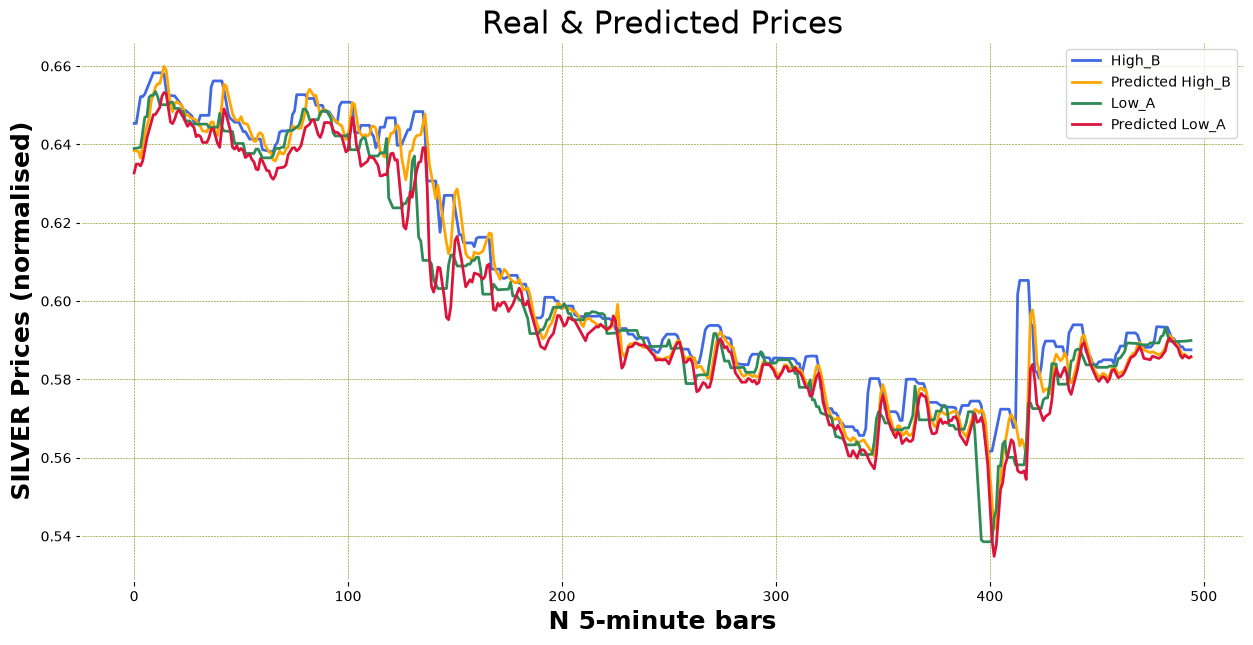

In [107]:
N1=2500 
LL = 500  
N2=N1+LL

plt.ion()
fig = plt.figure(figsize=(15,7))  

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test[N1:N2,0], label='High_B', color='royalblue')
line2, = ax1.plot(pred[N1:N2,0], label='Predicted High_B', color='orange')
line3, = ax1.plot(y_test[N1:N2,1], label='Low_A', color = 'seagreen')
line4, = ax1.plot(pred[N1:N2,1], label='Predicted Low_A', color='crimson')

plt.title('Real & Predicted Prices', size=22)
plt.ylabel('SILVER Prices (normalised)', size=18) 
plt.xlabel('N 5-minute bars', size=18)
plt.grid(True, color='olive', linestyle='--')
plt.legend(loc='upper right') 

plt.show()

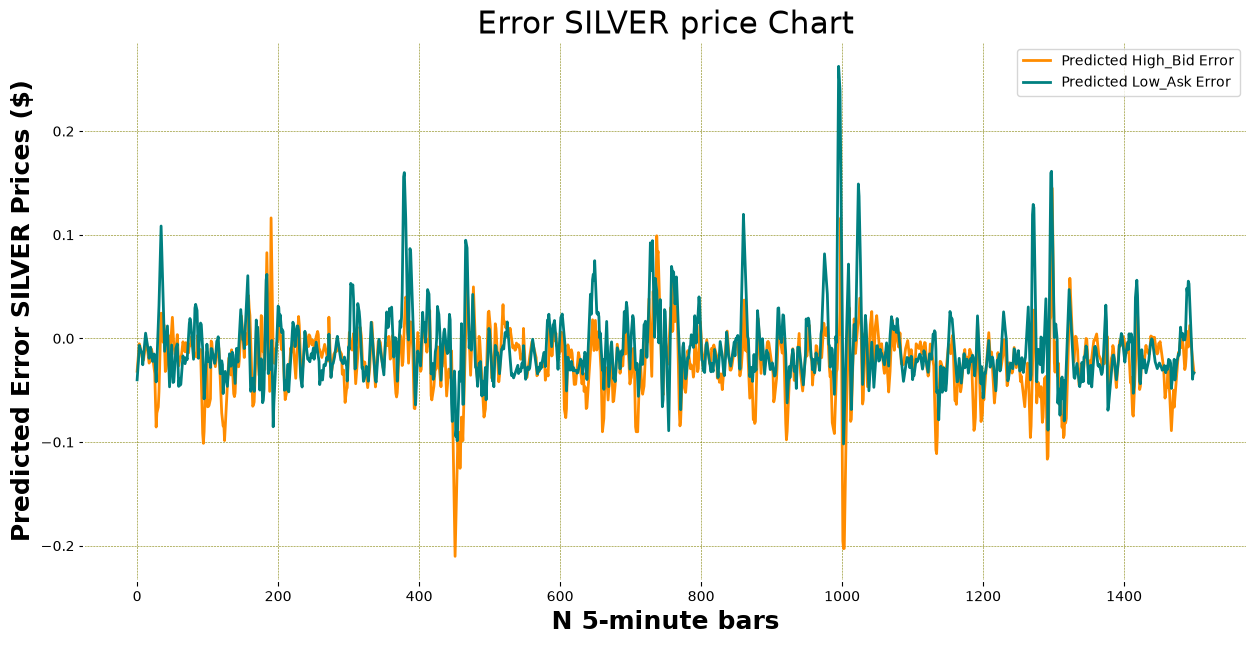

In [108]:
N1=0 
LL = 1500  
N2=N1+LL  

plt.ion()
fig = plt.figure(figsize=(15,7))  

ax1 = fig.add_subplot(111)

a = (pred[N1:N2,0] - y_test[N1:N2,0]) *(max_price-min_price)  
b = (pred[N1:N2,1] - y_test[N1:N2,1]) *(max_price-min_price)


line1, = ax1.plot(a, label='Predicted High_Bid Error', color='darkorange')
line2, = ax1.plot(b, label='Predicted Low_Ask Error', color='teal')

plt.title('Error SILVER price Chart', size=22)   
plt.ylabel('Predicted Error SILVER Prices ($)', size=18)   
plt.xlabel('N 5-minute bars', size=18)
plt.grid(True, color='olive', linestyle='--')
plt.legend(loc='upper right') 

plt.show()

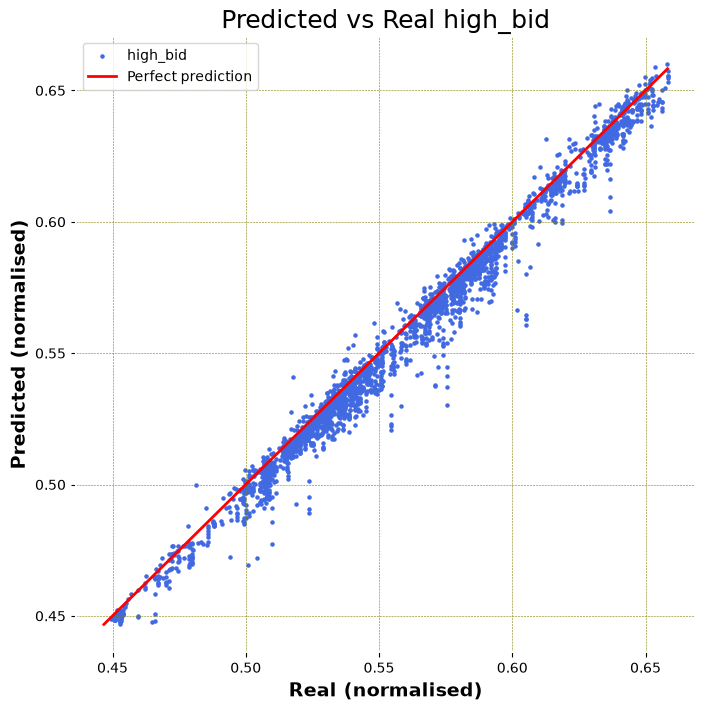

In [109]:
plt.figure(figsize=(8,8))
plt.scatter(y_test[:, 0], pred[:, 0], s=5, color='royalblue', label='high_bid')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', label='Perfect prediction')
plt.title('Predicted vs Real high_bid', size=18)
plt.xlabel('Real (normalised)', size=14)
plt.ylabel('Predicted (normalised)', size=14)
plt.grid(True, color='olive', linestyle='--')
plt.legend()
plt.show()

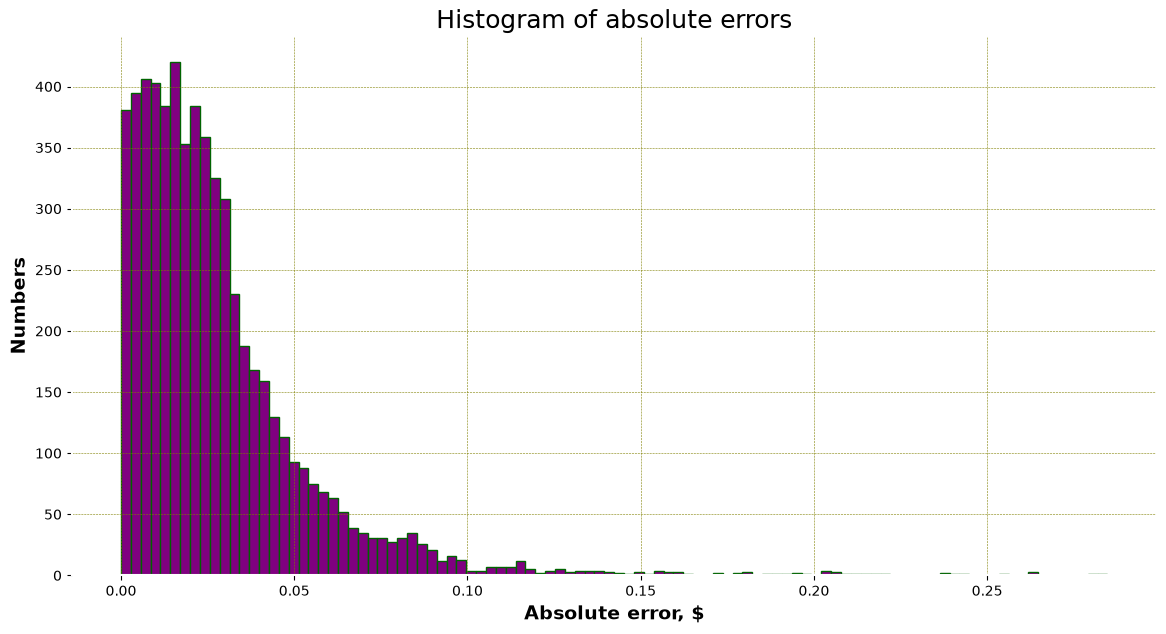

In [110]:
abs_error = np.abs(pred - y_test) * (max_price - min_price)
plt.figure(figsize=(14,7))
plt.hist(abs_error.flatten(), bins=100, color='purple', edgecolor='darkgreen')
plt.title('Histogram of absolute errors', size=18)
plt.xlabel('Absolute error, $', size=14)
plt.ylabel('Numbers', size=14)
plt.grid(True, color='olive', linestyle='--')
plt.show()

In [111]:
pred = LSTM_saved_best_model.predict(X_test)
pred_dollars = pred * (max_price - min_price) + min_price
real_dollars = y_test * (max_price - min_price) + min_price

result = pd.DataFrame({'Predicted max High_B ($)': pred_dollars[:,0],
                       'Real max High_B ($)': real_dollars[:,0],
                       'Predicted min Low_A ($)': pred_dollars[:,1],
                       'Real min Low_A ($)': real_dollars[:,1]})
result.tail(5).round(3)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step


,Predicted max High_B ($),Real max High_B ($),Predicted min Low_A ($),Real min Low_A ($)
2990,23.561,23.574,23.556,23.583
2991,23.562,23.569,23.560,23.583
2992,23.559,23.569,23.558,23.583
2993,23.556,23.569,23.556,23.584
2994,23.557,23.569,23.558,23.584


Model: ___ (LSTM / MLP / CNN). It reads the last ___ five-minute bars and predicts the highest Bid high and the lowest Ask low over the next ___ minutes.

Result: test MSE = ___ and test MAE = ___ (normalised), which is about ___ on a silver price near
___.

Training: the training and validation curves ___ (both fall / validation rises), so the model ___ overfit. The best model was saved at epoch ___.

Prediction: the predicted lines ___ the real prices. The error chart shows larger mistakes during ___.

Limit: only ___ months of data were used, so the model should be tested on other periods.